In [1]:
import os
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from xgboost import XGBRegressor

import warnings
warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
DATA_DIR = Path(r"D:\Coding\thesis")

CSV_FILE = DATA_DIR / "daily_tourism_demand_forecasting_2000_2015.csv"

raw = pd.read_csv(CSV_FILE)

print("Dataset loaded successfully.")
print("Shape:", raw.shape)

display(raw.head())

Dataset loaded successfully.
Shape: (29220, 8)


,Date,Destination,Visitor_Count,Hotel_Occupancy,Flight_Arrivals,Average_Temperature,Economic_Index,Major_Event
0,2000-01-01,Paris,152,91.861719,34,24.279758,1.098658,Festival
1,2000-01-01,Tokyo,152,77.833310,94,13.369956,0.833709,Festival
2,2000-01-01,New York,153,88.322903,41,-2.743537,1.221999,Festival
3,2000-01-01,London,207,68.493564,83,34.688462,1.117482,Exhibition
4,2000-01-01,Berlin,107,80.990257,68,15.990986,0.899861,Exhibition


In [3]:
TIME_COL = "Date"
TARGET_COL = "Visitor_Count"
DESTINATION_COL = "Destination"

SELECTED_DESTINATION = "Paris"

data = raw.copy()

data[TIME_COL] = pd.to_datetime(data[TIME_COL], errors="raise")

data = data[
    data[DESTINATION_COL] == SELECTED_DESTINATION
].copy()

data = data.sort_values(TIME_COL).reset_index(drop=True)

print("Selected Destination:", SELECTED_DESTINATION)
print("Number of records:", len(data))

display(data.head())

Selected Destination: Paris
Number of records: 5844


,Date,Destination,Visitor_Count,Hotel_Occupancy,Flight_Arrivals,Average_Temperature,Economic_Index,Major_Event
0,2000-01-01,Paris,152,91.861719,34,24.279758,1.098658,Festival
1,2000-01-02,Paris,269,98.950221,34,13.242799,1.285176,Conference
2,2000-01-03,Paris,84,96.372816,55,2.289444,1.255361,Festival
3,2000-01-04,Paris,237,81.707843,60,6.850940,0.665267,Exhibition
4,2000-01-05,Paris,86,89.184247,54,13.888597,0.619594,NaN


In [4]:
print("Missing values:")
display(data.isnull().sum())

print("Duplicate dates:", data[TIME_COL].duplicated().sum())

print("Date range:")
print(data[TIME_COL].min(), "to", data[TIME_COL].max())

print("Date frequency:")
print(data[TIME_COL].diff().value_counts().head())

Missing values:


Date                      0
Destination               0
Visitor_Count             0
Hotel_Occupancy           0
Flight_Arrivals           0
Average_Temperature       0
Economic_Index            0
Major_Event            1175
dtype: int64

Duplicate dates: 0
Date range:
2000-01-01 00:00:00 to 2015-12-31 00:00:00
Date frequency:
Date
1 days    5843
Name: count, dtype: int64


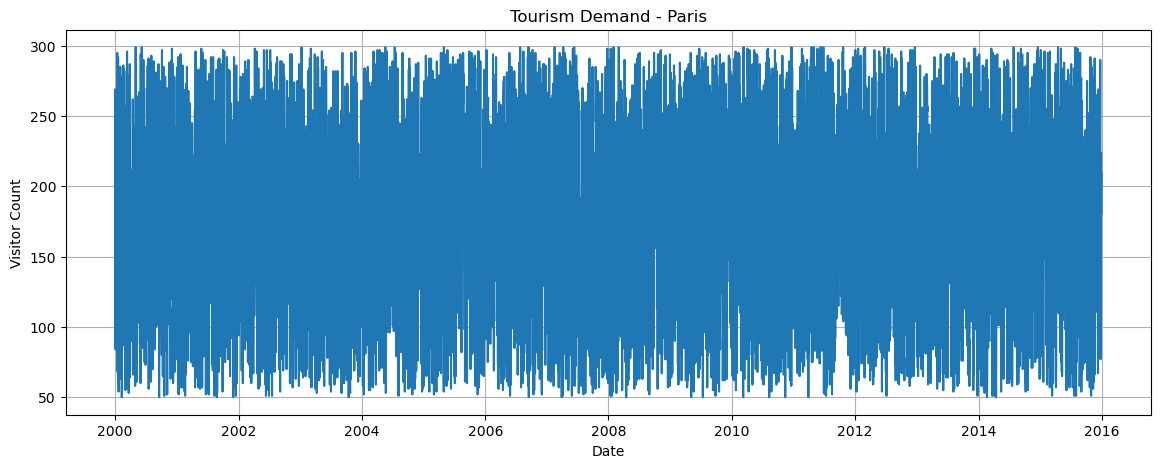

In [5]:
data = data.dropna(subset=[TARGET_COL]).copy()

values = data[TARGET_COL].values.astype(np.float32)

dates = data[TIME_COL].values

plt.figure(figsize=(14, 5))
plt.plot(data[TIME_COL], values)

plt.title(f"Tourism Demand - {SELECTED_DESTINATION}")
plt.xlabel("Date")
plt.ylabel("Visitor Count")
plt.grid(True)
plt.show()

In [6]:
LOOKBACK = 30
HORIZON = 1

TRAIN_FRAC = 0.70
VAL_FRAC = 0.15

N_ESTIMATORS = 1000
MAX_DEPTH = 5
LEARNING_RATE = 0.03

print("LOOKBACK:", LOOKBACK)
print("HORIZON:", HORIZON)

LOOKBACK: 30
HORIZON: 1


In [7]:
n = len(values)

train_end = int(n * TRAIN_FRAC)
val_end = int(n * (TRAIN_FRAC + VAL_FRAC))

print("Total samples:", n)
print("Train end:", train_end)
print("Validation end:", val_end)

print("\nTrain:", 0, "to", train_end - 1)
print("Validation:", train_end, "to", val_end - 1)
print("Test:", val_end, "to", n - 1)

Total samples: 5844
Train end: 4090
Validation end: 4967

Train: 0 to 4089
Validation: 4090 to 4966
Test: 4967 to 5843


In [8]:
scaler = StandardScaler()

scaler.fit(values[:train_end].reshape(-1, 1))

scaled_values = scaler.transform(
    values.reshape(-1, 1)
).flatten()

print("Scaling completed.")

Scaling completed.


In [9]:
def create_lag_features(values, lookback, horizon=1):

    X = []
    y = []
    target_indices = []

    for target_idx in range(lookback, len(values) - horizon + 1):

        x = values[target_idx - lookback:target_idx]

        target = values[
            target_idx:target_idx + horizon
        ]

        X.append(x)
        y.append(target)
        target_indices.append(target_idx)

    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32).reshape(-1)

    target_indices = np.asarray(target_indices)

    return X, y, target_indices


X, y, target_indices = create_lag_features(
    scaled_values,
    LOOKBACK,
    HORIZON
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target indices:", target_indices.shape)

X shape: (5814, 30)
y shape: (5814,)
Target indices: (5814,)


In [10]:
train_mask = target_indices < train_end

val_mask = (
    (target_indices >= train_end) &
    (target_indices < val_end)
)

test_mask = target_indices >= val_end

X_train = X[train_mask]
y_train = y[train_mask]

X_val = X[val_mask]
y_val = y[val_mask]

X_test = X[test_mask]
y_test = y[test_mask]

idx_train = target_indices[train_mask]
idx_val = target_indices[val_mask]
idx_test = target_indices[test_mask]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (4060, 30) (4060,)
Validation: (877, 30) (877,)
Testing: (877, 30) (877,)


In [11]:
xgb_model = XGBRegressor(
    n_estimators=N_ESTIMATORS,
    max_depth=MAX_DEPTH,
    learning_rate=LEARNING_RATE,

    subsample=0.8,
    colsample_bytree=0.8,

    objective="reg:squarederror",
    eval_metric="rmse",

    random_state=SEED,
    n_jobs=-1,

    early_stopping_rounds=30
)

xgb_model.fit(
    X_train,
    y_train,

    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],

    verbose=50
)

print("Training completed.")

[0]	validation_0-rmse:0.99844	validation_1-rmse:0.98781
[50]	validation_0-rmse:0.94342	validation_1-rmse:0.98488
[87]	validation_0-rmse:0.90760	validation_1-rmse:0.98613
Training completed.


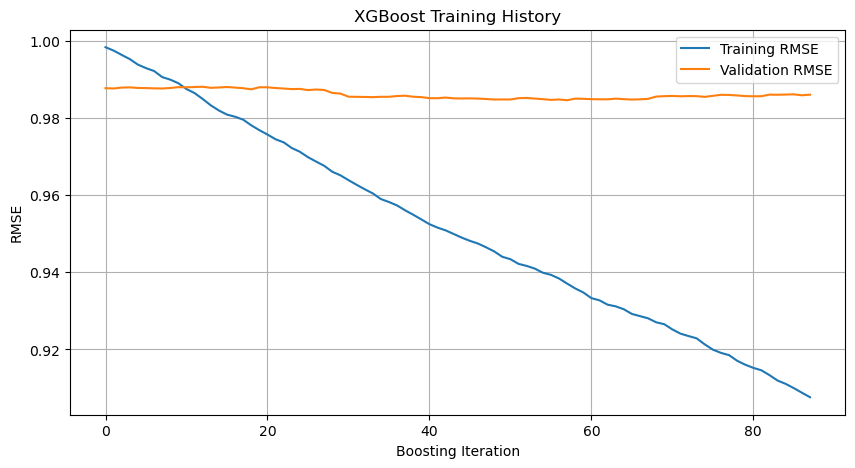

Best iteration: 57


In [12]:
results = xgb_model.evals_result()

train_rmse = results["validation_0"]["rmse"]
val_rmse = results["validation_1"]["rmse"]

plt.figure(figsize=(10, 5))

plt.plot(train_rmse, label="Training RMSE")
plt.plot(val_rmse, label="Validation RMSE")

plt.xlabel("Boosting Iteration")
plt.ylabel("RMSE")
plt.title("XGBoost Training History")

plt.legend()
plt.grid(True)
plt.show()

print("Best iteration:", xgb_model.best_iteration)

In [13]:
pred_scaled = xgb_model.predict(X_test)

pred_original = scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).flatten()

y_test_original = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

print("Prediction completed.")
print("Predictions:", len(pred_original))

Prediction completed.
Predictions: 877


In [14]:
def calculate_smape(y_true, y_pred):

    denominator = (
        np.abs(y_true) + np.abs(y_pred)
    ) / 2

    denominator = np.maximum(denominator, 1e-8)

    return np.mean(
        np.abs(y_true - y_pred) / denominator
    ) * 100


mae = mean_absolute_error(
    y_test_original,
    pred_original
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_original,
        pred_original
    )
)

smape_value = calculate_smape(
    y_test_original,
    pred_original
)

print("XGBoost Evaluation")
print("----------------------")
print(f"MAE:   {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"sMAPE: {smape_value:.2f}%")

XGBoost Evaluation
----------------------
MAE:   63.3597
RMSE:  72.8436
sMAPE: 38.89%


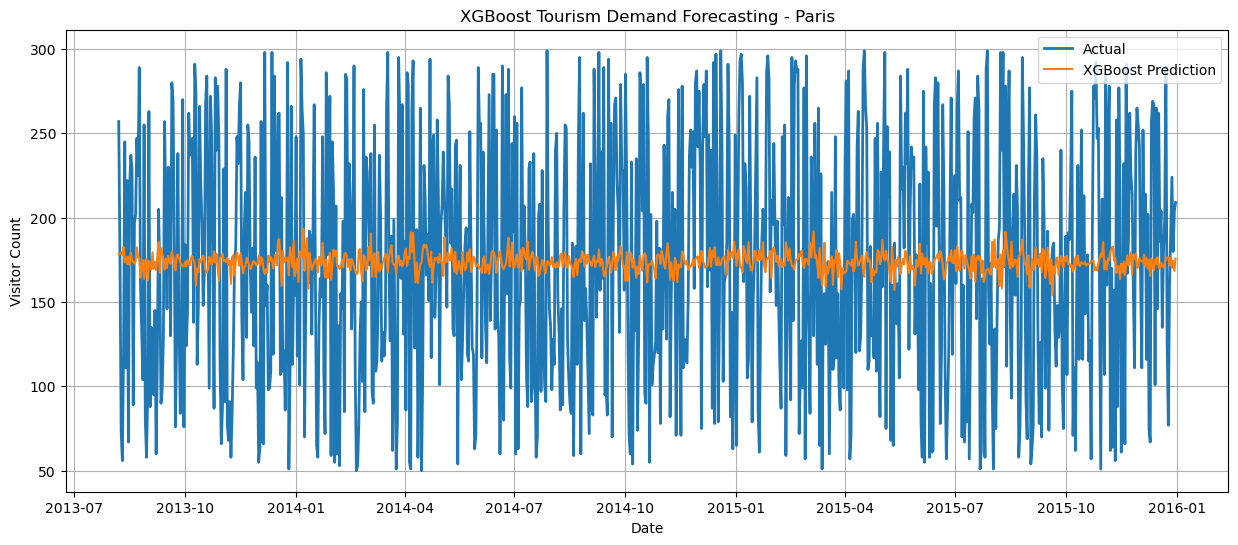

In [15]:
test_dates = data.iloc[idx_test][TIME_COL].values

plt.figure(figsize=(15, 6))

plt.plot(
    test_dates,
    y_test_original,
    label="Actual",
    linewidth=2
)

plt.plot(
    test_dates,
    pred_original,
    label="XGBoost Prediction",
    linewidth=1.5
)

plt.title(
    f"XGBoost Tourism Demand Forecasting - {SELECTED_DESTINATION}"
)

plt.xlabel("Date")
plt.ylabel("Visitor Count")

plt.legend()
plt.grid(True)
plt.show()

,Feature,Importance
24,Lag_25,0.039405
25,Lag_26,0.039277
14,Lag_15,0.037842
27,Lag_28,0.037752
26,Lag_27,0.037731
18,Lag_19,0.037103
20,Lag_21,0.037016
12,Lag_13,0.036306
19,Lag_20,0.036271
15,Lag_16,0.036240


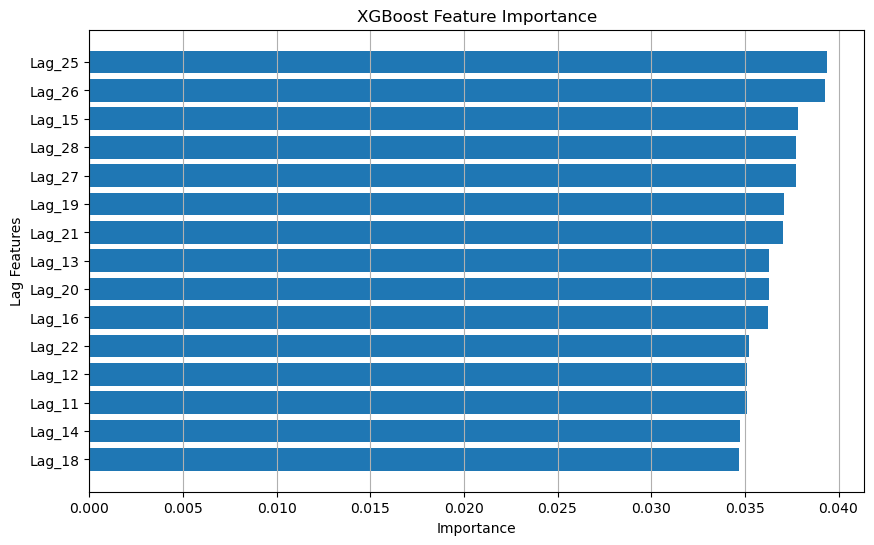

In [16]:
importance = xgb_model.feature_importances_

feature_names = [
    f"Lag_{i}"
    for i in range(1, LOOKBACK + 1)
]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"].head(15)[::-1],
    importance_df["Importance"].head(15)[::-1]
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Lag Features")

plt.grid(axis="x")
plt.show()

In [17]:
OUTPUT_DIR = Path("xgboost_results")
OUTPUT_DIR.mkdir(exist_ok=True)

# Save model
joblib.dump(
    xgb_model,
    OUTPUT_DIR / f"xgboost_{SELECTED_DESTINATION}.joblib"
)

# Save scaler
joblib.dump(
    scaler,
    OUTPUT_DIR / f"scaler_{SELECTED_DESTINATION}.joblib"
)

# Save predictions
prediction_df = pd.DataFrame({
    "Date": test_dates,
    "Actual": y_test_original,
    "Predicted": pred_original
})

prediction_df.to_csv(
    OUTPUT_DIR / f"xgboost_predictions_{SELECTED_DESTINATION}.csv",
    index=False
)

# Save evaluation metrics
metrics_df = pd.DataFrame({
    "Model": ["XGBoost"],
    "Destination": [SELECTED_DESTINATION],
    "MAE": [mae],
    "RMSE": [rmse],
    "sMAPE": [smape_value]
})

metrics_df.to_csv(
    OUTPUT_DIR / f"xgboost_metrics_{SELECTED_DESTINATION}.csv",
    index=False
)

print("Model and results saved successfully.")
print("Output directory:", OUTPUT_DIR.resolve())

Model and results saved successfully.
Output directory: D:\Coding\thesis\xgboost_results


# Global XGBoost

In [1]:
import os
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from xgboost import XGBRegressor

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("XGBoost version:", __import__("xgboost").__version__)
print("Libraries imported successfully.")

XGBoost version: 3.2.0
Libraries imported successfully.


In [2]:
DATA_DIR = Path(r"D:\Coding\thesis")

CSV_FILE = DATA_DIR / "daily_tourism_demand_forecasting_2000_2015.csv"

raw = pd.read_csv(CSV_FILE)

print("Dataset loaded successfully.")
print("Shape:", raw.shape)

display(raw.head())

Dataset loaded successfully.
Shape: (29220, 8)


,Date,Destination,Visitor_Count,Hotel_Occupancy,Flight_Arrivals,Average_Temperature,Economic_Index,Major_Event
0,2000-01-01,Paris,152,91.861719,34,24.279758,1.098658,Festival
1,2000-01-01,Tokyo,152,77.833310,94,13.369956,0.833709,Festival
2,2000-01-01,New York,153,88.322903,41,-2.743537,1.221999,Festival
3,2000-01-01,London,207,68.493564,83,34.688462,1.117482,Exhibition
4,2000-01-01,Berlin,107,80.990257,68,15.990986,0.899861,Exhibition


In [3]:
TIME_COL = "Date"
TARGET_COL = "Visitor_Count"
DESTINATION_COL = "Destination"

CITIES = [
    "Paris",
    "Tokyo",
    "New York",
    "London",
    "Berlin"
]

data = raw.copy()

data[TIME_COL] = pd.to_datetime(
    data[TIME_COL],
    errors="raise"
)

data = data[
    data[DESTINATION_COL].isin(CITIES)
].copy()

data = data.dropna(
    subset=[TIME_COL, DESTINATION_COL, TARGET_COL]
)

data = data.sort_values(
    [DESTINATION_COL, TIME_COL]
).reset_index(drop=True)

print("Selected cities:")
print(data[DESTINATION_COL].unique())

print("\nRecords per city:")
display(data.groupby(DESTINATION_COL).size())

print("\nDataset shape:", data.shape)

display(data.head())

Selected cities:
['Berlin' 'London' 'New York' 'Paris' 'Tokyo']

Records per city:


Destination
Berlin      5844
London      5844
New York    5844
Paris       5844
Tokyo       5844
dtype: int64


Dataset shape: (29220, 8)


,Date,Destination,Visitor_Count,Hotel_Occupancy,Flight_Arrivals,Average_Temperature,Economic_Index,Major_Event
0,2000-01-01,Berlin,107,80.990257,68,15.990986,0.899861,Exhibition
1,2000-01-02,Berlin,141,77.606100,90,19.399866,1.333195,Cultural Event
2,2000-01-03,Berlin,89,93.781354,72,18.470047,1.465255,Exhibition
3,2000-01-04,Berlin,61,73.235921,67,9.832730,1.168841,Conference
4,2000-01-05,Berlin,278,69.971689,34,25.222046,0.728798,Conference


In [4]:
print("Missing values:")
display(data.isnull().sum())

duplicates = data.duplicated(
    subset=[DESTINATION_COL, TIME_COL]
).sum()

print("Duplicate city-date records:", duplicates)

print("\nDate range by city:")

date_summary = data.groupby(DESTINATION_COL)[TIME_COL].agg(
    ["min", "max", "count"]
)

display(date_summary)

Missing values:


Date                      0
Destination               0
Visitor_Count             0
Hotel_Occupancy           0
Flight_Arrivals           0
Average_Temperature       0
Economic_Index            0
Major_Event            5870
dtype: int64

Duplicate city-date records: 0

Date range by city:


,min,max,count
Destination,,,
Berlin,2000-01-01,2015-12-31,5844
London,2000-01-01,2015-12-31,5844
New York,2000-01-01,2015-12-31,5844
Paris,2000-01-01,2015-12-31,5844
Tokyo,2000-01-01,2015-12-31,5844


In [5]:
for city in CITIES:

    city_data = data[
        data[DESTINATION_COL] == city
    ].sort_values(TIME_COL)

    date_diff = city_data[TIME_COL].diff().dropna()

    missing_intervals = (
        date_diff != pd.Timedelta(days=1)
    ).sum()

    print(
        city,
        "| Missing daily intervals:",
        missing_intervals
    )

Paris | Missing daily intervals: 0
Tokyo | Missing daily intervals: 0
New York | Missing daily intervals: 0
London | Missing daily intervals: 0
Berlin | Missing daily intervals: 0


In [6]:
LOOKBACK = 30
HORIZON = 1

TRAIN_FRAC = 0.70
VAL_FRAC = 0.15

N_ESTIMATORS = 1000
MAX_DEPTH = 5
LEARNING_RATE = 0.03

SUBSAMPLE = 0.8
COLSAMPLE_BYTREE = 0.8

EARLY_STOPPING_ROUNDS = 30

print("LOOKBACK:", LOOKBACK)
print("HORIZON:", HORIZON)
print("Number of cities:", len(CITIES))

LOOKBACK: 30
HORIZON: 1
Number of cities: 5


In [7]:
city_to_id = {
    city: idx
    for idx, city in enumerate(CITIES)
}

city_onehot = pd.get_dummies(
    data[DESTINATION_COL],
    prefix="City",
    dtype=np.float32
)

data = pd.concat(
    [data, city_onehot],
    axis=1
)

CITY_FEATURES = [
    f"City_{city}"
    for city in CITIES
]

display(
    data[
        [DESTINATION_COL] + CITY_FEATURES
    ].drop_duplicates().sort_values(DESTINATION_COL)
)

,Destination,City_Paris,City_Tokyo,City_New York,City_London,City_Berlin
0,Berlin,0.0,0.0,0.0,0.0,1.0
5844,London,0.0,0.0,0.0,1.0,0.0
11688,New York,0.0,0.0,1.0,0.0,0.0
17532,Paris,1.0,0.0,0.0,0.0,0.0
23376,Tokyo,0.0,1.0,0.0,0.0,0.0


In [8]:
unique_dates = np.sort(
    data[TIME_COL].unique()
)

n_dates = len(unique_dates)

train_end = int(n_dates * TRAIN_FRAC)
val_end = int(n_dates * (TRAIN_FRAC + VAL_FRAC))

train_cutoff = unique_dates[train_end]
val_cutoff = unique_dates[val_end]

print("Total unique dates:", n_dates)

print("\nTrain:")
print(unique_dates[0], "to", unique_dates[train_end - 1])

print("\nValidation:")
print(unique_dates[train_end], "to", unique_dates[val_end - 1])

print("\nTest:")
print(unique_dates[val_end], "to", unique_dates[-1])

Total unique dates: 5844

Train:
2000-01-01T00:00:00.000000000 to 2011-03-13T00:00:00.000000000

Validation:
2011-03-14T00:00:00.000000000 to 2013-08-06T00:00:00.000000000

Test:
2013-08-07T00:00:00.000000000 to 2015-12-31T00:00:00.000000000


In [9]:
scaler = StandardScaler()

train_values = data.loc[
    data[TIME_COL] < train_cutoff,
    TARGET_COL
].values.reshape(-1, 1)

scaler.fit(train_values)

data["Visitor_Scaled"] = scaler.transform(
    data[[TARGET_COL]]
).flatten()

print("Global scaling completed.")
print("Scaler mean:", scaler.mean_)
print("Scaler scale:", scaler.scale_)

Global scaling completed.
Scaler mean: [174.58889976]
Scaler scale: [72.17356589]


In [10]:
def create_global_lag_features(
    data,
    cities,
    lookback,
    horizon,
    train_cutoff,
    val_cutoff
):

    X_train, y_train = [], []
    X_val, y_val = [], []
    X_test, y_test = [], []

    city_train, date_train = [], []
    city_val, date_val = [], []
    city_test, date_test = [], []

    for city in cities:

        city_data = data[
            data[DESTINATION_COL] == city
        ].sort_values(TIME_COL).reset_index(drop=True)

        values = city_data[
            "Visitor_Scaled"
        ].values.astype(np.float32)

        city_features = city_data[
            CITY_FEATURES
        ].values.astype(np.float32)

        city_dates = city_data[TIME_COL].values

        for target_idx in range(
            lookback,
            len(city_data) - horizon + 1
        ):

            x_start = target_idx - lookback

            # Check continuity of the historical window
            window_dates = pd.to_datetime(
                city_dates[x_start:target_idx + 1]
            )

            if not np.all(
                np.diff(window_dates.values) ==
                np.timedelta64(1, "D")
            ):
                continue

            target_date = pd.Timestamp(
                city_dates[target_idx]
            )

            # Historical visitor count
            lag_features = values[
                x_start:target_idx
            ]

            # City one-hot features
            city_feature = city_features[target_idx]

            # Combine Lag and City features
            x = np.concatenate([
                lag_features,
                city_feature
            ])

            # Target: next-day visitor count
            y = values[
                target_idx:target_idx + horizon
            ]

            if target_date < train_cutoff:

                X_train.append(x)
                y_train.append(y[0])
                city_train.append(city)
                date_train.append(target_date)

            elif target_date < val_cutoff:

                X_val.append(x)
                y_val.append(y[0])
                city_val.append(city)
                date_val.append(target_date)

            else:

                X_test.append(x)
                y_test.append(y[0])
                city_test.append(city)
                date_test.append(target_date)

    return (
        np.asarray(X_train, dtype=np.float32),
        np.asarray(y_train, dtype=np.float32),
        city_train,
        date_train,

        np.asarray(X_val, dtype=np.float32),
        np.asarray(y_val, dtype=np.float32),
        city_val,
        date_val,

        np.asarray(X_test, dtype=np.float32),
        np.asarray(y_test, dtype=np.float32),
        city_test,
        date_test
    )

In [11]:
(
    X_train, y_train, city_train, date_train,
    X_val, y_val, city_val, date_val,
    X_test, y_test, city_test, date_test
) = create_global_lag_features(
    data=data,
    cities=CITIES,
    lookback=LOOKBACK,
    horizon=HORIZON,
    train_cutoff=train_cutoff,
    val_cutoff=val_cutoff
)

print("Training:")
print("X:", X_train.shape)
print("y:", y_train.shape)

print("\nValidation:")
print("X:", X_val.shape)
print("y:", y_val.shape)

print("\nTesting:")
print("X:", X_test.shape)
print("y:", y_test.shape)

Training:
X: (20300, 35)
y: (20300,)

Validation:
X: (4385, 35)
y: (4385,)

Testing:
X: (4385, 35)
y: (4385,)


In [12]:
LAG_FEATURES = [
    f"Lag_{i}"
    for i in range(1, LOOKBACK + 1)
]

FEATURE_NAMES = LAG_FEATURES + CITY_FEATURES

print("Total features:", len(FEATURE_NAMES))
print(FEATURE_NAMES)

Total features: 35
['Lag_1', 'Lag_2', 'Lag_3', 'Lag_4', 'Lag_5', 'Lag_6', 'Lag_7', 'Lag_8', 'Lag_9', 'Lag_10', 'Lag_11', 'Lag_12', 'Lag_13', 'Lag_14', 'Lag_15', 'Lag_16', 'Lag_17', 'Lag_18', 'Lag_19', 'Lag_20', 'Lag_21', 'Lag_22', 'Lag_23', 'Lag_24', 'Lag_25', 'Lag_26', 'Lag_27', 'Lag_28', 'Lag_29', 'Lag_30', 'City_Paris', 'City_Tokyo', 'City_New York', 'City_London', 'City_Berlin']


In [13]:
xgb_model = XGBRegressor(
    n_estimators=N_ESTIMATORS,
    max_depth=MAX_DEPTH,
    learning_rate=LEARNING_RATE,

    subsample=SUBSAMPLE,
    colsample_bytree=COLSAMPLE_BYTREE,

    objective="reg:squarederror",
    eval_metric="rmse",

    random_state=SEED,
    n_jobs=-1,

    early_stopping_rounds=EARLY_STOPPING_ROUNDS
)

print("Global XGBoost model initialized.")

Global XGBoost model initialized.


In [14]:
xgb_model.fit(
    X_train,
    y_train,

    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],

    verbose=50
)

print("Global XGBoost training completed.")
print("Best iteration:", xgb_model.best_iteration)

[0]	validation_0-rmse:0.99973	validation_1-rmse:0.99009
[40]	validation_0-rmse:0.98599	validation_1-rmse:0.99028
Global XGBoost training completed.
Best iteration: 10


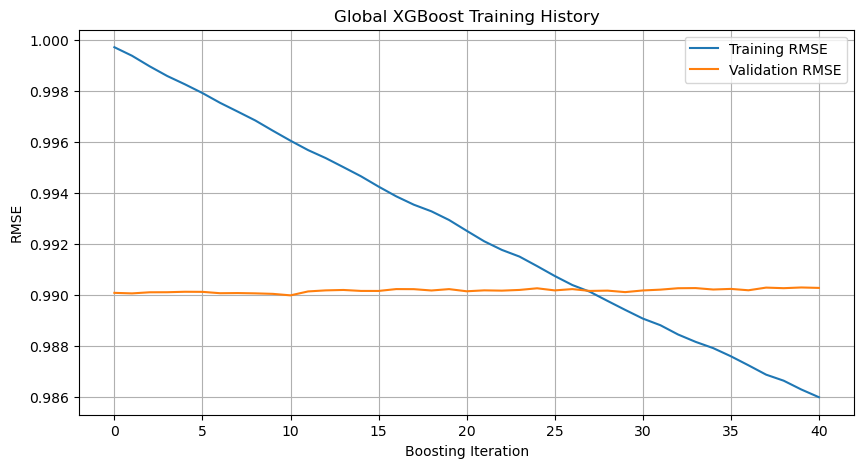

In [15]:
results = xgb_model.evals_result()

train_rmse = results["validation_0"]["rmse"]
val_rmse = results["validation_1"]["rmse"]

plt.figure(figsize=(10, 5))

plt.plot(
    train_rmse,
    label="Training RMSE"
)

plt.plot(
    val_rmse,
    label="Validation RMSE"
)

plt.title("Global XGBoost Training History")
plt.xlabel("Boosting Iteration")
plt.ylabel("RMSE")

plt.legend()
plt.grid(True)
plt.show()

In [16]:
pred_scaled = xgb_model.predict(X_test)

pred_original = scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).flatten()

y_test_original = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

print("Prediction completed.")
print("Number of predictions:", len(pred_original))

Prediction completed.
Number of predictions: 4385


In [17]:
def calculate_smape(y_true, y_pred):

    denominator = (
        np.abs(y_true) + np.abs(y_pred)
    ) / 2

    denominator = np.maximum(
        denominator,
        1e-8
    )

    return np.mean(
        np.abs(y_true - y_pred) / denominator
    ) * 100


mae = mean_absolute_error(
    y_test_original,
    pred_original
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_original,
        pred_original
    )
)

smape_value = calculate_smape(
    y_test_original,
    pred_original
)

print("Global XGBoost Evaluation")
print("-------------------------")
print(f"MAE:   {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"sMAPE: {smape_value:.2f}%")

Global XGBoost Evaluation
-------------------------
MAE:   63.0126
RMSE:  72.7203
sMAPE: 38.74%


In [18]:
prediction_df = pd.DataFrame({
    "Date": pd.to_datetime(date_test),
    "Destination": city_test,
    "Actual": y_test_original,
    "Predicted": pred_original
})

prediction_df = prediction_df.sort_values(
    ["Destination", "Date"]
).reset_index(drop=True)

display(prediction_df.head(10))

,Date,Destination,Actual,Predicted
0,2013-08-07,Berlin,101.999992,174.249847
1,2013-08-08,Berlin,267.000000,172.505692
2,2013-08-09,Berlin,249.000000,174.269806
3,2013-08-10,Berlin,197.000000,171.629562
4,2013-08-11,Berlin,97.000000,174.622238
5,2013-08-12,Berlin,288.000000,175.342224
6,2013-08-13,Berlin,126.000000,174.612122
7,2013-08-14,Berlin,176.000000,175.734940
8,2013-08-15,Berlin,77.000000,173.647385
9,2013-08-16,Berlin,65.000000,174.522110


In [19]:
city_results = []

for city in CITIES:

    city_result = prediction_df[
        prediction_df["Destination"] == city
    ]

    actual = city_result["Actual"].values
    predicted = city_result["Predicted"].values

    city_mae = mean_absolute_error(
        actual,
        predicted
    )

    city_rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    city_smape = calculate_smape(
        actual,
        predicted
    )

    city_results.append({
        "Destination": city,
        "Samples": len(city_result),
        "MAE": city_mae,
        "RMSE": city_rmse,
        "sMAPE (%)": city_smape
    })

city_metrics = pd.DataFrame(city_results)

display(city_metrics)

,Destination,Samples,MAE,RMSE,sMAPE (%)
0,Paris,877,63.440365,72.879988,38.923630
1,Tokyo,877,64.264603,73.933944,39.671772
2,New York,877,61.438835,71.526338,38.210564
3,London,877,61.955448,71.559883,37.859066
4,Berlin,877,63.963482,73.665898,39.049175


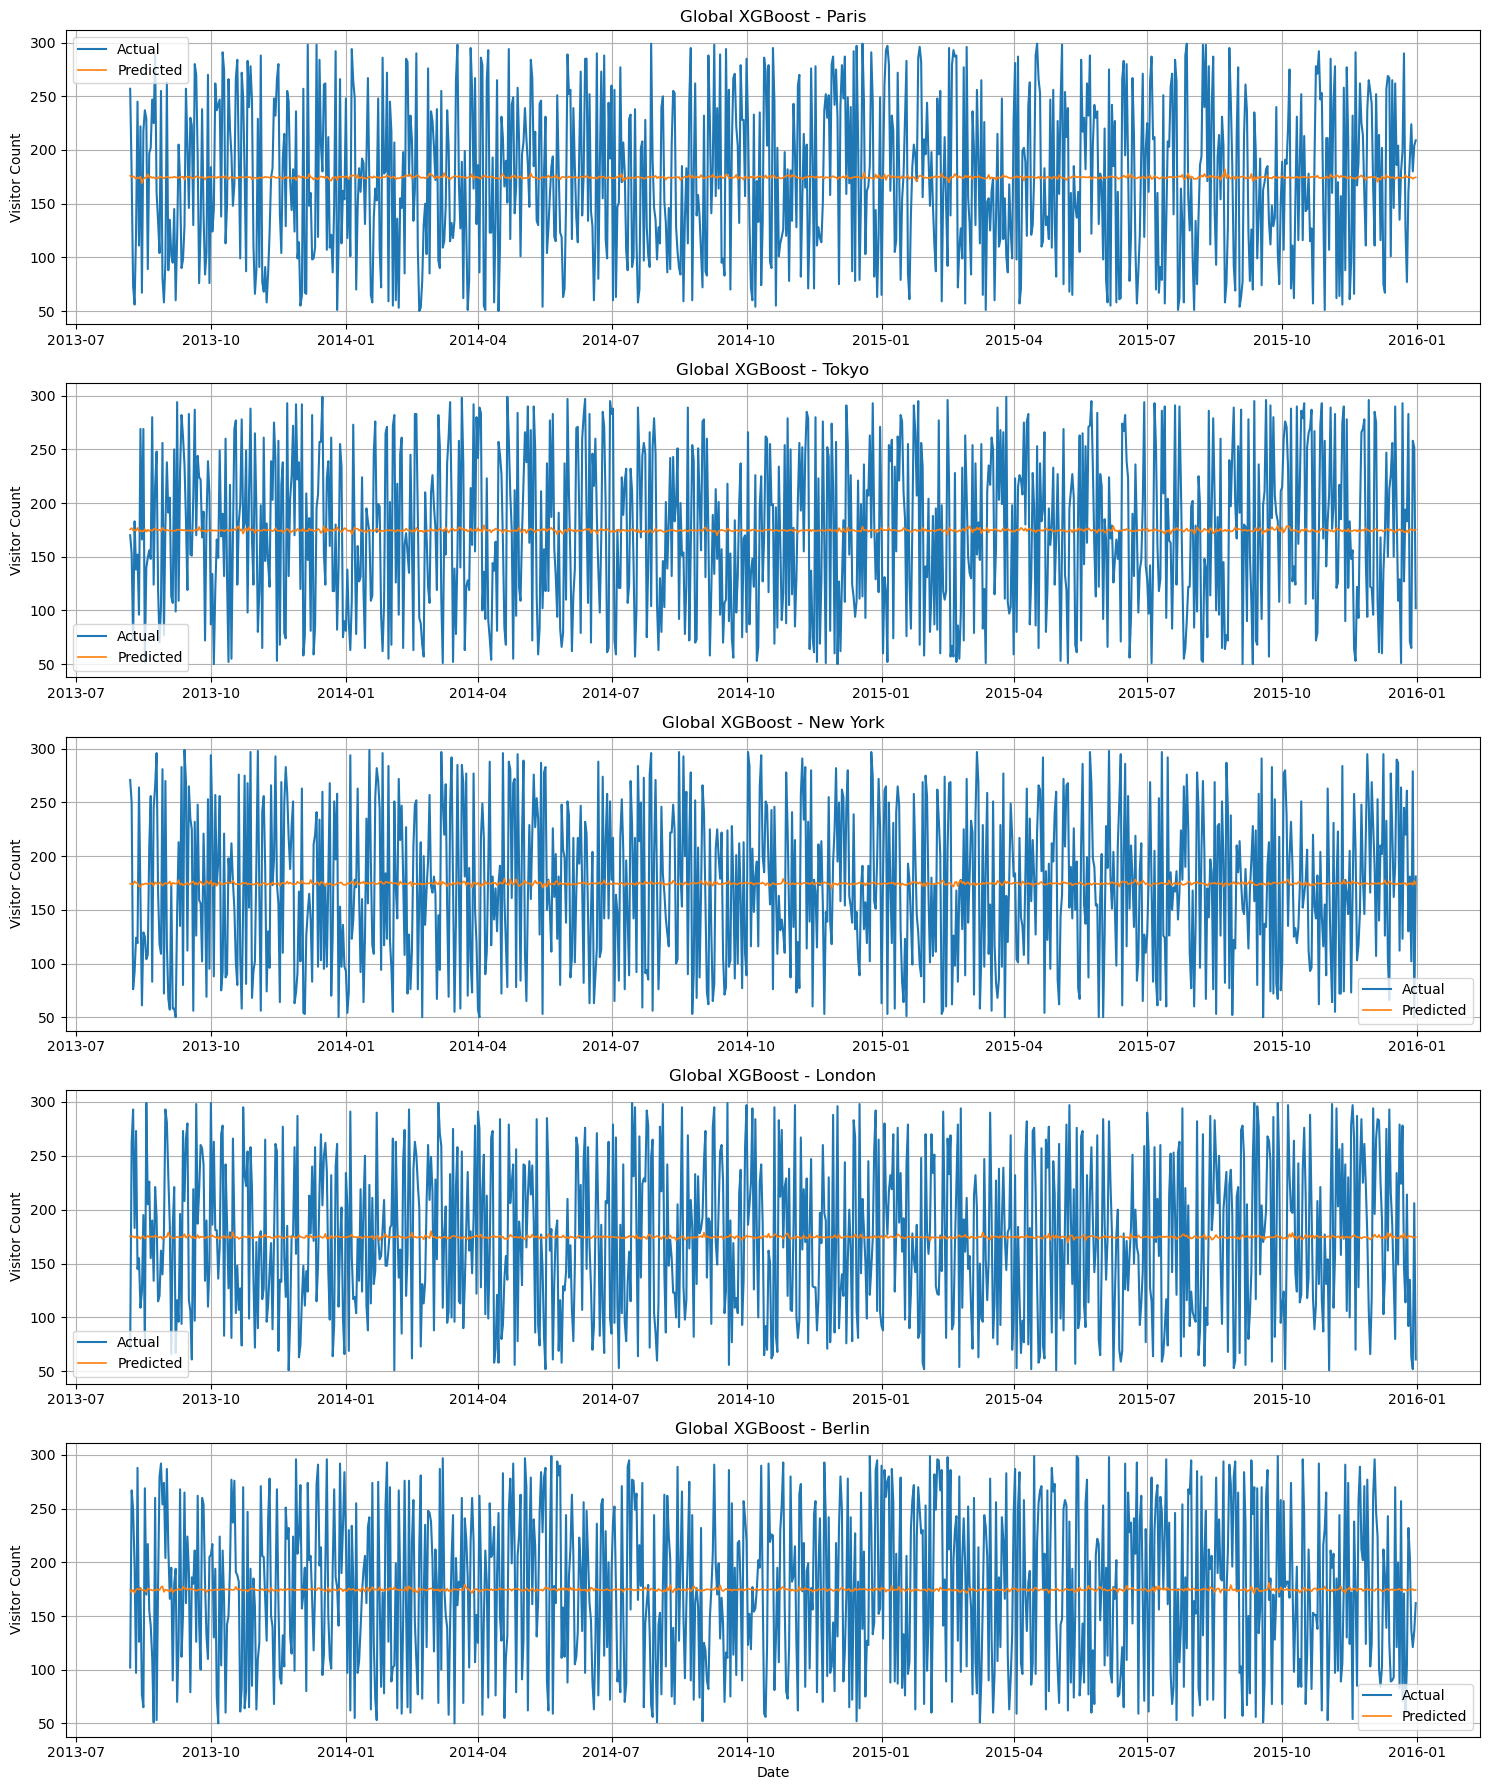

In [20]:
fig, axes = plt.subplots(
    len(CITIES),
    1,
    figsize=(15, 18)
)

for ax, city in zip(axes, CITIES):

    city_result = prediction_df[
        prediction_df["Destination"] == city
    ].sort_values("Date")

    ax.plot(
        city_result["Date"],
        city_result["Actual"],
        label="Actual",
        linewidth=1.5
    )

    ax.plot(
        city_result["Date"],
        city_result["Predicted"],
        label="Predicted",
        linewidth=1.2
    )

    ax.set_title(f"Global XGBoost - {city}")
    ax.set_ylabel("Visitor Count")
    ax.legend()
    ax.grid(True)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

,Feature,Importance
0,City_Tokyo,0.034491
1,Lag_25,0.032854
2,Lag_26,0.032247
3,Lag_15,0.032246
4,Lag_30,0.032160
5,Lag_13,0.032116
6,Lag_20,0.031914
7,Lag_24,0.031440
8,Lag_11,0.031192
9,Lag_23,0.031053


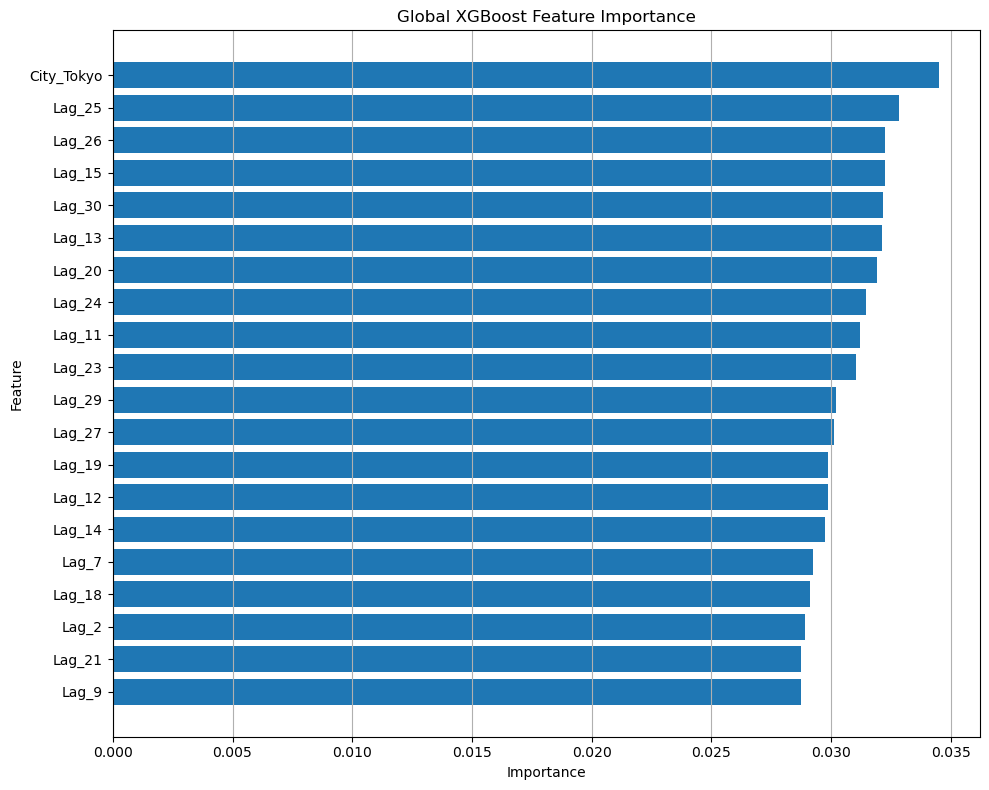

In [21]:
importance_df = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Importance": xgb_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df)

plt.figure(figsize=(10, 8))

top_features = importance_df.head(20).sort_values(
    "Importance",
    ascending=True
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Global XGBoost Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.grid(axis="x")
plt.tight_layout()
plt.show()

In [22]:
OUTPUT_DIR = Path("global_xgboost_results")
OUTPUT_DIR.mkdir(exist_ok=True)

# Save model
joblib.dump(
    xgb_model,
    OUTPUT_DIR / "global_xgboost.joblib"
)

# Save scaler
joblib.dump(
    scaler,
    OUTPUT_DIR / "global_xgboost_scaler.joblib"
)

# Save city mapping
joblib.dump(
    city_to_id,
    OUTPUT_DIR / "global_xgboost_city_mapping.joblib"
)

# Save feature names
joblib.dump(
    FEATURE_NAMES,
    OUTPUT_DIR / "global_xgboost_feature_names.joblib"
)

# Save predictions
prediction_df.to_csv(
    OUTPUT_DIR / "global_xgboost_predictions.csv",
    index=False
)

# Save city metrics
city_metrics.to_csv(
    OUTPUT_DIR / "global_xgboost_city_metrics.csv",
    index=False
)

# Save overall metrics
overall_metrics = pd.DataFrame({
    "Model": ["Global XGBoost"],
    "MAE": [mae],
    "RMSE": [rmse],
    "sMAPE (%)": [smape_value]
})

overall_metrics.to_csv(
    OUTPUT_DIR / "global_xgboost_overall_metrics.csv",
    index=False
)

# Save feature importance
importance_df.to_csv(
    OUTPUT_DIR / "global_xgboost_feature_importance.csv",
    index=False
)

print("All files saved successfully.")
print("Output directory:", OUTPUT_DIR.resolve())

All files saved successfully.
Output directory: D:\Coding\thesis\global_xgboost_results
